
Caso 1
K = 2,  zeta = 0.5,  wn = 100 rad/s

Funcion de transferencia:
<TransferFunction>: sys[0]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

             2
  -----------------------
  0.0001 s^2 + 0.01 s + 1
Polos (tf): [-50.+86.60254038j -50.-86.60254038j]
Polos (ss): [-50.+86.60254038j -50.-86.60254038j]

Variables de estado:
<StateSpace>: sys[1]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
States (2): ['x[0]', 'x[1]']

A = [[ 100.  100.]
     [-300. -200.]]

B = [[  0.]
     [100.]]

C = [[2. 0.]]

D = [[0.]]
Diferencia maxima tf vs ss:     1.255e-13 V

Caso 2
K = 2.5,  zeta = 0.25,  wn = 100 rad/s

Funcion de transferencia:
<TransferFunction>: sys[3]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

            2.5
  ------------------------
  0.0001 s^2 + 0.005 s + 1
Polos (tf): [-25.+96.82458366j -25.-96.82458366j]
Polos (ss): [-25.+96.82458366j -25.-96.82458366j]

Variables de estado:
<StateSpace>: sys[4]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']
States (2): ['x[0]', 'x[1]']

A = [[ 1

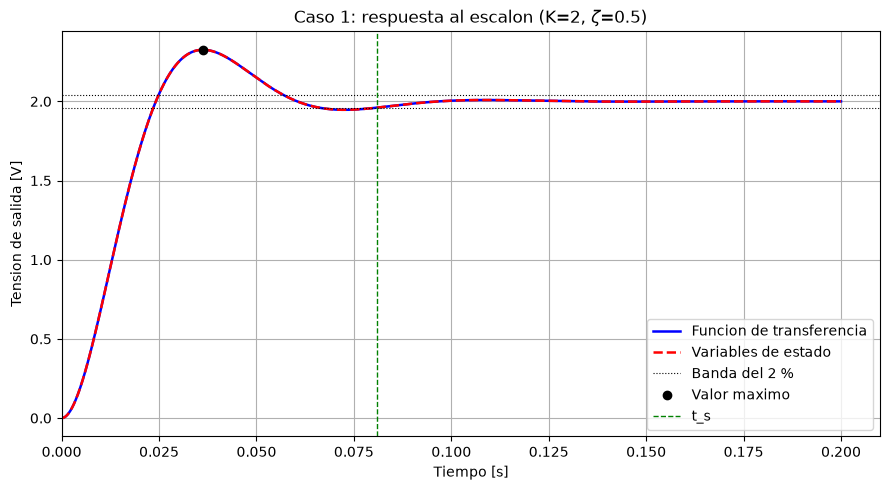

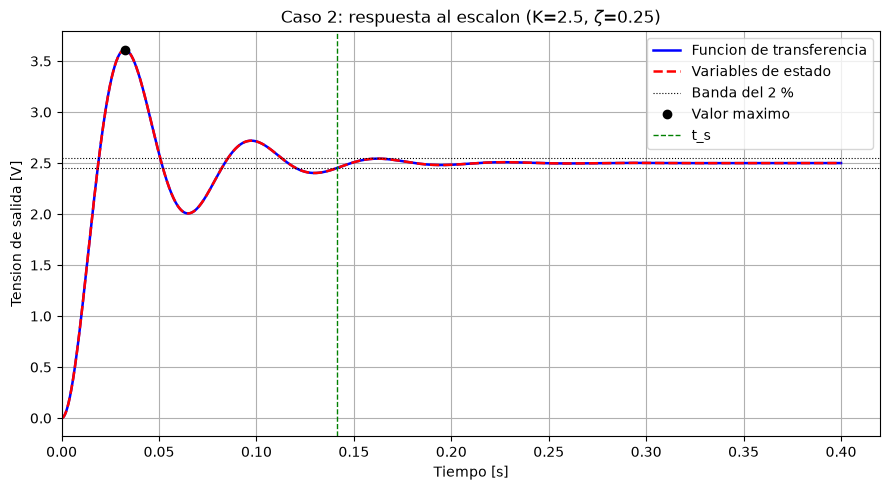

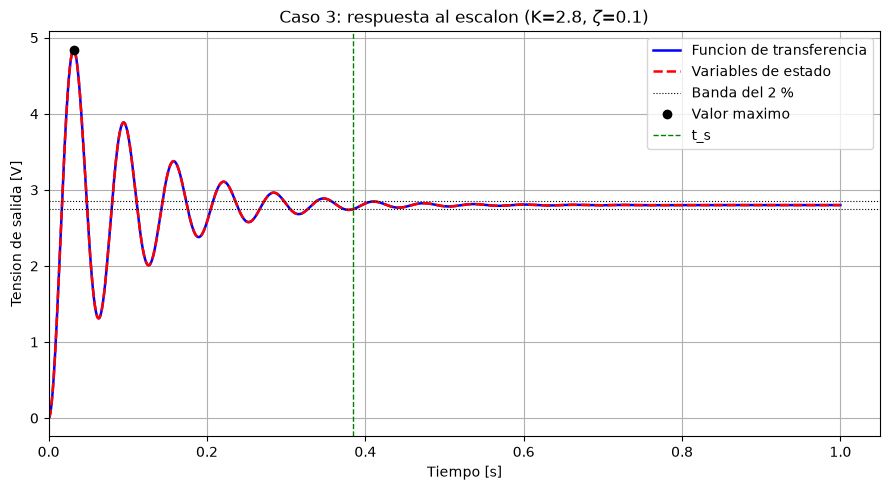

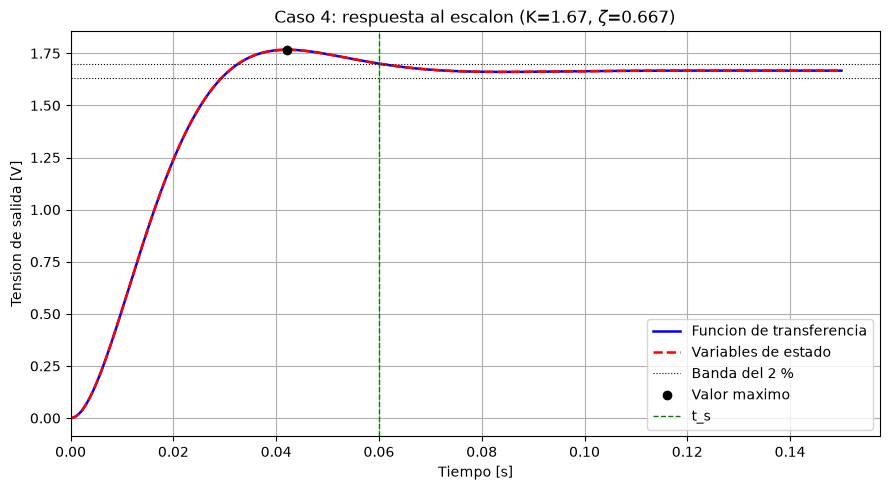

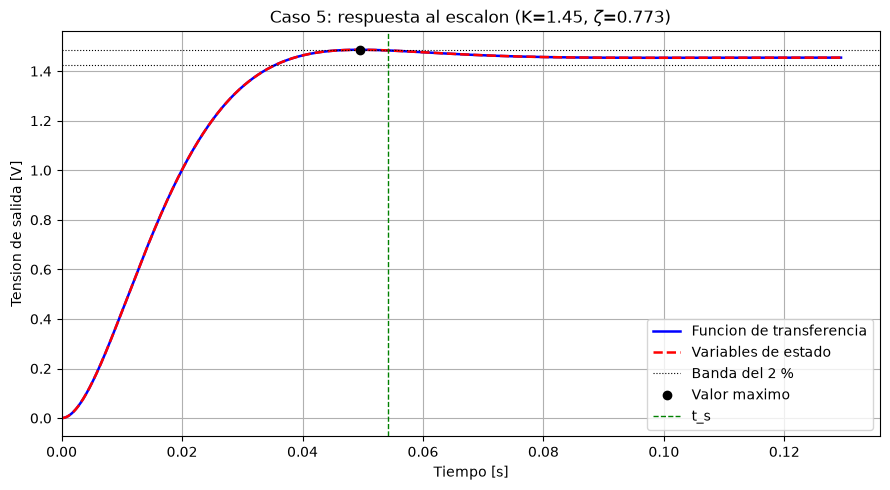

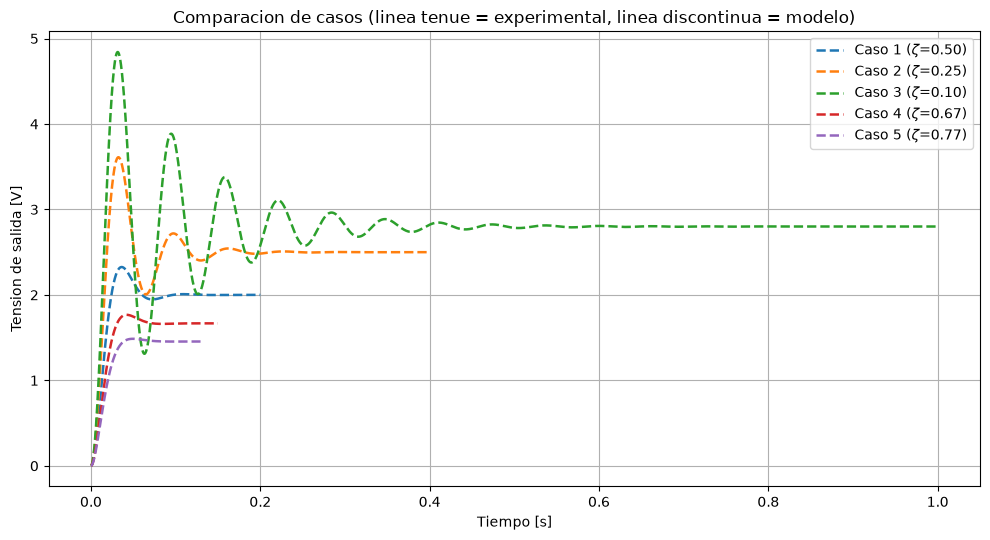

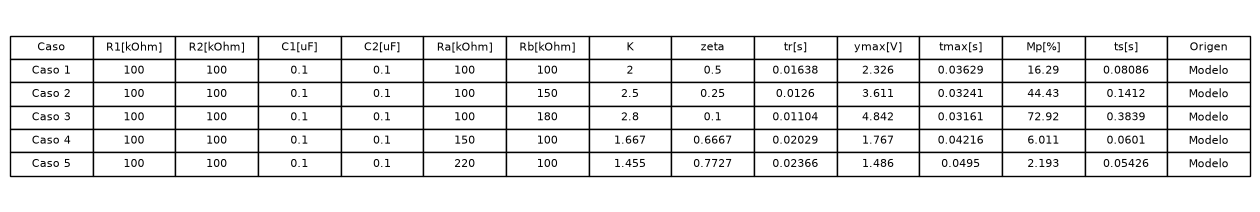

In [1]:
import os
import re

import numpy as np
import control as ct
import matplotlib.pyplot as plt

# ============================================================
# PRACTICA 2 - CIRCUITO SALLEN-KEY DE SEGUNDO ORDEN
# Puntos 6.3 y 6.4 del informe
#
#   6.3  Modelo por funcion de transferencia y por variables de
#        estado, respuesta temporal y comparacion con el
#        experimento.
#   6.4  Tiempo de subida, valor maximo, tiempo al valor maximo,
#        sobreimpulso maximo y tiempo de establecimiento a partir
#        de los datos experimentales (tabla comparativa).
#
# Requisitos:  pip install control numpy matplotlib
# ============================================================


# ============================================================
# 0. CONFIGURACION  (EDITAR AQUI)
# ============================================================

# Valores MEDIDOS con el multimetro (en Ohm y Faradio).
# 'archivo' = CSV exportado del osciloscopio para ese caso.
# Si 'archivo' es None, se simula el modelo sin comparar con el experimento.
#
# Los casos 2 a 5 son SOLO EJEMPLOS: reemplazar por los valores
# que indique el docente. Recordar que para K >= 3 el sistema es inestable.
CASOS = [
    dict(nombre="Caso 1", R1=100e3, R2=100e3, C1=0.1e-6, C2=0.1e-6,
         Ra=100e3, Rb=100e3, archivo=None),
    dict(nombre="Caso 2", R1=100e3, R2=100e3, C1=0.1e-6, C2=0.1e-6,
         Ra=100e3, Rb=150e3, archivo=None),
    dict(nombre="Caso 3", R1=100e3, R2=100e3, C1=0.1e-6, C2=0.1e-6,
         Ra=100e3, Rb=180e3, archivo=None),
    dict(nombre="Caso 4", R1=100e3, R2=100e3, C1=0.1e-6, C2=0.1e-6,
         Ra=150e3, Rb=100e3, archivo=None),
    dict(nombre="Caso 5", R1=100e3, R2=100e3, C1=0.1e-6, C2=0.1e-6,
         Ra=220e3, Rb=100e3, archivo=None),
]

# Columnas del CSV del osciloscopio (empezando en 0):
# tiempo, entrada vi(t), salida vo(t)
COL_T, COL_VI, COL_VO = 0, 1, 2

# True  -> el modelo se excita con la entrada real medida vi(t)
# False -> el modelo se excita con un escalon ideal de amplitud
#          igual a la medida en el osciloscopio
USAR_ENTRADA_REAL = True

# Ventana de media movil [muestras] para calcular los parametros
# experimentales (1 = sin suavizado). Usar 5 a 15 si hay mucho ruido.
SUAVIZADO = 1

# Banda del tiempo de establecimiento (2 %)
BANDA_TS = 0.02

# Amplitud del escalon [V] cuando no hay datos experimentales
V_PASO_SIM = 1.0

# Carpeta donde se guardan graficos y tabla
CARPETA = "resultados"
os.makedirs(CARPETA, exist_ok=True)


# ============================================================
# 1. MODELOS DEL CIRCUITO (funcion de transferencia y estados)
# ============================================================

def construir_modelos(R1, R2, C1, C2, Ra, Rb):

    K = 1 + Rb / Ra

    # ---- Funcion de transferencia (punto 6.1)
    # G(s) = K / (R1R2C1C2 s^2 + [R1C2 + R2C2 + (1-K)R1C1] s + 1)
    a2 = R1 * R2 * C1 * C2
    a1 = R1 * C2 + R2 * C2 + (1 - K) * R1 * C1

    G = ct.tf([K], [a2, a1, 1])

    wn = 1 / np.sqrt(a2)
    zeta = a1 / (2 * np.sqrt(a2))

    # ---- Variables de estado (punto 6.2)
    # x1 = vC2 = v2 ,  x2 = vC1 = v1 - vo ,  u = vi ,  y = vo = K x1
    A = [
        [(K - 1) / (R2 * C2), 1 / (R2 * C2)],
        [-(K / (R1 * C1) + (K - 1) / (R2 * C1)),
         -(1 / (R1 * C1) + 1 / (R2 * C1))]
    ]

    B = [
        [0],
        [1 / (R1 * C1)]
    ]

    C_ss = [
        [K, 0]
    ]

    D = [
        [0]
    ]

    G_ss = ct.ss(A, B, C_ss, D)

    return dict(K=K, zeta=zeta, wn=wn, G=G, G_ss=G_ss,
                A=np.array(A), den=[a2, a1, 1])


# ============================================================
# 2. LECTURA DE DATOS DEL OSCILOSCOPIO
# ============================================================

def cargar_csv(ruta):
    """Lee un CSV (tiempo, vi, vo). Ignora encabezados y lineas de texto."""
    filas = []
    n_min = max(COL_T, COL_VI, COL_VO) + 1

    with open(ruta, encoding="utf-8-sig", errors="ignore") as f:
        for linea in f:
            linea = linea.strip()
            if not linea:
                continue
            if ";" in linea:      # separador ';' con coma decimal
                partes = [p.replace(",", ".") for p in linea.split(";")]
            else:
                partes = re.split(r"[,\t]", linea)
            try:
                vals = [float(p) for p in partes if p.strip() != ""]
            except ValueError:
                continue          # linea de encabezado
            if len(vals) >= n_min:
                filas.append([vals[COL_T], vals[COL_VI], vals[COL_VO]])

    if len(filas) < 10:
        raise ValueError(f"No se pudieron leer datos validos en {ruta}")

    datos = np.array(filas)
    return datos[:, 0], datos[:, 1], datos[:, 2]


def extraer_escalon(t, vi, vo):
    """
    Toma un flanco de subida de la onda cuadrada y devuelve:
      t_u      : tiempo uniforme desde 0 (inicio del segmento)
      u, y     : entrada y salida sin el nivel inicial (parten de 0)
      t_borde  : instante del flanco dentro de t_u
      V_paso   : amplitud del escalon [V]
    """
    v_bajo, v_alto = np.percentile(vi, 2), np.percentile(vi, 98)
    umbral = (v_bajo + v_alto) / 2

    sube = np.where((vi[:-1] < umbral) & (vi[1:] >= umbral))[0] + 1
    baja = np.where((vi[:-1] >= umbral) & (vi[1:] < umbral))[0] + 1

    i0 = i1 = n_pre = None
    for k in sube:
        sig = baja[baja > k]
        fin = sig[0] if len(sig) else len(t)
        n = max(5, int(0.1 * (fin - k)))
        if k - n >= 0 and fin - k > 20:
            i0, i1, n_pre = k, fin, n
            break
    if i0 is None:
        raise ValueError("No se encontro un flanco de subida completo en la senal vi(t).")

    # Nivel previo al flanco (ultimo tramo del semiciclo bajo)
    corte = max(2, n_pre // 3)
    pre = slice(i0 - n_pre, i0 - corte)
    vi_base = np.mean(vi[pre])
    vo_base = np.mean(vo[pre])

    i_ini = i0 - corte
    ts_seg = t[i_ini:i1]
    u_seg = vi[i_ini:i1] - vi_base
    y_seg = vo[i_ini:i1] - vo_base

    # Remuestreo a malla uniforme (requerido por forced_response)
    t_u = np.linspace(0, ts_seg[-1] - ts_seg[0], len(ts_seg))
    u = np.interp(t_u, ts_seg - ts_seg[0], u_seg)
    y = np.interp(t_u, ts_seg - ts_seg[0], y_seg)

    t_borde = t[i0] - t[i_ini]
    V_paso = np.mean(u[len(u) // 2:])
    return t_u, u, y, t_borde, V_paso


# ============================================================
# 3. PARAMETROS DE LA RESPUESTA TEMPORAL (punto 6.4)
# ============================================================

def media_movil(y, n):
    if n <= 1:
        return y
    y_pad = np.pad(y, (n // 2, n - 1 - n // 2), mode="edge")
    return np.convolve(y_pad, np.ones(n) / n, mode="valid")


def metricas(t, y, banda=BANDA_TS, suavizado=1):
    """tr, ymax, tmax, Mp, ts, y_inf de una respuesta a escalon (t desde 0)."""
    y = media_movil(np.asarray(y, dtype=float), suavizado)
    t = np.asarray(t, dtype=float)

    y_inf = np.mean(y[int(0.9 * len(y)):])      # valor final (ultimo 10 %)
    signo = 1.0 if y_inf >= 0 else -1.0
    yy = signo * y
    yf = abs(y_inf)

    def cruce(nivel):
        idx = np.where(yy >= nivel)[0]
        if len(idx) == 0:
            return np.nan
        k = idx[0]
        if k == 0:
            return t[0]
        return t[k - 1] + (nivel - yy[k - 1]) / (yy[k] - yy[k - 1]) * (t[k] - t[k - 1])

    t10, t90 = cruce(0.1 * yf), cruce(0.9 * yf)
    tr = t90 - t10

    i_max = int(np.argmax(yy))
    ymax = y[i_max]
    tmax = t[i_max]
    Mp = max(0.0, (yy[i_max] - yf) / yf * 100)

    fuera = np.abs(y - y_inf) > banda * yf
    if not fuera.any():
        ts = 0.0
    elif fuera[-1]:
        ts = np.nan                               # no se establece en la ventana
    else:
        ts = t[np.where(fuera)[0][-1] + 1]

    return dict(tr=tr, ymax=ymax, tmax=tmax, Mp=Mp, ts=ts, yinf=y_inf)


# ============================================================
# 4. SIMULACION Y PROCESAMIENTO DE CADA CASO
# ============================================================

def fmt(x, dec=4):
    return "-" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{dec}g}"


resultados = []

for caso in CASOS:
    nombre = caso["nombre"]
    print("\n" + "=" * 60)
    print(nombre)
    print("=" * 60)

    m = construir_modelos(caso["R1"], caso["R2"], caso["C1"], caso["C2"],
                          caso["Ra"], caso["Rb"])
    G, G_ss = m["G"], m["G_ss"]

    print("K = {:.4g},  zeta = {:.4g},  wn = {:.4g} rad/s".format(
        m["K"], m["zeta"], m["wn"]))
    if m["K"] >= 3:
        print("ADVERTENCIA: K >= 3 -> sistema inestable (zeta <= 0).")
    print("\nFuncion de transferencia:")
    print(G)
    print("Polos (tf):", np.roots(m["den"]))
    print("Polos (ss):", np.linalg.eigvals(m["A"]))
    print("\nVariables de estado:")
    print(G_ss)

    # ---------- Datos experimentales (si existen)
    hay_exp = caso["archivo"] is not None and os.path.exists(caso["archivo"])
    if caso["archivo"] is not None and not hay_exp:
        print(f"AVISO: no se encontro '{caso['archivo']}'. Solo se simula.")

    if hay_exp:
        t_raw, vi_raw, vo_raw = cargar_csv(caso["archivo"])
        t_u, u, y_exp, t_borde, V_paso = extraer_escalon(t_raw, vi_raw, vo_raw)
        print(f"Escalon de entrada medido: {V_paso:.4g} V")

        if USAR_ENTRADA_REAL:
            t_s, y_tf = ct.forced_response(G, T=t_u, U=u)
            t_s, y_ss = ct.forced_response(G_ss, T=t_u, U=u)
        else:
            t_s, y_tf = ct.step_response(G, T=t_u)
            t_s, y_ss = ct.step_response(G_ss, T=t_u)
            y_tf, y_ss = V_paso * np.squeeze(y_tf), V_paso * np.squeeze(y_ss)
    else:
        # Solo simulacion: ventana segun el polo mas lento
        polos = np.roots(m["den"])
        sigma = np.min(np.abs(polos.real)) if np.all(polos.real < 0) else 10.0
        t_borde = 0.0
        t_u = np.linspace(0, 10 / sigma, 5000)
        t_s, y_tf = ct.step_response(G, T=t_u)
        t_s, y_ss = ct.step_response(G_ss, T=t_u)
        y_tf, y_ss = V_PASO_SIM * np.squeeze(y_tf), V_PASO_SIM * np.squeeze(y_ss)
        y_exp = None

    y_tf, y_ss = np.squeeze(y_tf), np.squeeze(y_ss)
    t_plot = t_u - t_borde            # t = 0 en el flanco del escalon
    mask = t_plot >= 0

    # ---------- Parametros (punto 6.4)
    met_sim = metricas(t_plot[mask], y_tf[mask])
    met_exp = None
    if y_exp is not None:
        met_exp = metricas(t_plot[mask], y_exp[mask], suavizado=SUAVIZADO)
        err_rms = np.sqrt(np.mean((y_exp[mask] - y_tf[mask]) ** 2))
        print(f"\nError RMS (experimental vs tf): {err_rms:.4g} V")
    dif_ss = np.max(np.abs(y_tf - y_ss))
    print(f"Diferencia maxima tf vs ss:     {dif_ss:.3e} V")

    resultados.append(dict(caso=caso, m=m, t=t_plot, mask=mask,
                           y_exp=y_exp, y_tf=y_tf, y_ss=y_ss,
                           met_exp=met_exp, met_sim=met_sim))

    # ---------- Grafico de cada caso (punto 6.3)
    fig, ax = plt.subplots(figsize=(9, 5))
    if y_exp is not None:
        ax.plot(t_plot, y_exp, color="0.6", lw=1.2, label="Experimental")
    ax.plot(t_plot, y_tf, "b", lw=1.8, label="Funcion de transferencia")
    ax.plot(t_plot, y_ss, "r--", lw=1.8, label="Variables de estado")

    ref = met_exp if met_exp is not None else met_sim
    ax.axhline(ref["yinf"] * (1 + BANDA_TS), color="k", ls=":", lw=0.8)
    ax.axhline(ref["yinf"] * (1 - BANDA_TS), color="k", ls=":", lw=0.8,
               label="Banda del 2 %")
    ax.plot(ref["tmax"], ref["ymax"], "ko", label="Valor maximo")
    if not np.isnan(ref["ts"]):
        ax.axvline(ref["ts"], color="g", ls="--", lw=1, label="t_s")

    ax.set_xlim(left=min(0, t_plot[0]))
    ax.set_xlabel("Tiempo [s]")
    ax.set_ylabel("Tension de salida [V]")
    ax.set_title(f"{nombre}: respuesta al escalon (K={m['K']:.3g}, "
                 f"$\\zeta$={m['zeta']:.3g})")
    ax.legend()
    ax.grid()
    fig.tight_layout()
    fig.savefig(os.path.join(CARPETA, f"{nombre.replace(' ', '_')}.png"), dpi=200)


# ============================================================
# 5. COMPARACION DE TODOS LOS CASOS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, r in enumerate(resultados):
    color = f"C{i}"
    if r["y_exp"] is not None:
        ax.plot(r["t"], r["y_exp"], color=color, alpha=0.45, lw=1.2)
    ax.plot(r["t"], r["y_tf"], "--", color=color, lw=1.8,
            label=f"{r['caso']['nombre']} ($\\zeta$={r['m']['zeta']:.2f})")

ax.set_xlabel("Tiempo [s]")
ax.set_ylabel("Tension de salida [V]")
ax.set_title("Comparacion de casos (linea tenue = experimental, "
             "linea discontinua = modelo)")
ax.legend()
ax.grid()
fig.tight_layout()
fig.savefig(os.path.join(CARPETA, "comparacion_casos.png"), dpi=200)


# ============================================================
# 6. TABLA COMPARATIVA (punto 6.4)
# ============================================================

encab = ["Caso", "R1[kOhm]", "R2[kOhm]", "C1[uF]", "C2[uF]", "Ra[kOhm]", "Rb[kOhm]",
         "K", "zeta", "tr[s]", "ymax[V]", "tmax[s]", "Mp[%]", "ts[s]", "Origen"]

filas = []
for r in resultados:
    c, m = r["caso"], r["m"]
    base = [c["nombre"], fmt(c["R1"] / 1e3), fmt(c["R2"] / 1e3),
            fmt(c["C1"] * 1e6), fmt(c["C2"] * 1e6),
            fmt(c["Ra"] / 1e3), fmt(c["Rb"] / 1e3), fmt(m["K"]), fmt(m["zeta"])]
    if r["met_exp"] is not None:
        e = r["met_exp"]
        filas.append(base + [fmt(e["tr"]), fmt(e["ymax"]), fmt(e["tmax"]),
                             fmt(e["Mp"]), fmt(e["ts"]), "Experimental"])
    s = r["met_sim"]
    filas.append(base + [fmt(s["tr"]), fmt(s["ymax"]), fmt(s["tmax"]),
                         fmt(s["Mp"]), fmt(s["ts"]), "Modelo"])


# CSV (se abre directo en Excel / Google Sheets)
with open(os.path.join(CARPETA, "tabla_comparativa.csv"), "w",
          encoding="utf-8-sig") as f:
    f.write(";".join(encab) + "\n")
    for fila in filas:
        f.write(";".join(str(x) for x in fila) + "\n")

# Imagen de la tabla (para pegar en el informe)
fig, ax = plt.subplots(figsize=(16, 0.5 + 0.4 * len(filas)))
ax.axis("off")
tabla = ax.table(cellText=filas, colLabels=encab, loc="center", cellLoc="center")
tabla.auto_set_font_size(False)
tabla.set_fontsize(8)
tabla.scale(1, 1.4)
fig.savefig(os.path.join(CARPETA, "tabla_comparativa.png"), dpi=200,
            bbox_inches="tight")

print(f"\nGraficos y tabla guardados en la carpeta '{CARPETA}'.")
plt.show()